# HighwayEnv and Q-learning from scratch

This notebook is a place to learn the driving environment before extending it for
adaptive sensor activation in your final project. Start with a small highway, see
what the agent observes, compress those observations into a table-sized state,
then implement and evaluate Q-learning yourself.

**You will practice:** `reset` / `step` / `render`, configuration, discrete driving
actions, state discretization, epsilon-greedy exploration, the Bellman update,
and evaluation on traffic seeds that were not used during training.

Run cells **from top to bottom**. The default is 200 training episodes and 30
evaluation episodes per policy. For a quick run, use 20 and 5; that checks the
workflow rather than establishing a good driving policy. No improvement or
convergence is assumed: the evaluation measures what this run actually learned.

This is a **driving-only baseline**. HighwayEnv's kinematics are simulated,
idealized observations, not physical sensor measurements. There are no sensor
switches or energy costs here yet. Standard collisions terminate the episode;
your proposed nonterminating collision design is a later extension.

## 1. Setup and imports

Use the project's `.venv` kernel; see `README.md` for launch instructions.
If you are using another kernel, uncomment the `%pip` line below, run it, then
restart the kernel and run from the top. `%pip` installs into the active kernel.
The version report helps identify a wrong interpreter or reproduce an experiment.

In [8]:
# %pip install -r requirements.txt

import os
# Offscreen rendering is configured below; dummy video disables HighwayEnv drawing.
os.environ.setdefault("SDL_AUDIODRIVER", "dummy")
os.environ.setdefault("PYGAME_HIDE_SUPPORT_PROMPT", "1")

import copy
import json
import sys
from pathlib import Path
from importlib.metadata import version

import gymnasium as gym
import highway_env  # Registers the environment IDs.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display

gym.register_envs(highway_env)
SEED = 42
PACKAGE_VERSIONS = {p: version(p) for p in
                    ["highway-env", "gymnasium", "numpy", "pandas", "matplotlib"]}
print("Python:", sys.version.split()[0])
print("Interpreter:", sys.executable)
print("Packages:", PACKAGE_VERSIONS)

Python: 3.13.15
Interpreter: <recorded conda Python interpreter>
Packages: {'highway-env': '1.12.1', 'gymnasium': '1.4.0', 'numpy': '2.5.4', 'pandas': '3.0.6', 'matplotlib': '3.11.2'}


## 2. Build a small highway

The **ego vehicle** is the car we control. Other vehicles use HighwayEnv's traffic
controllers. We use `highway-v0`, three lanes, and twelve traffic vehicles.

`simulation_frequency` is the physics rate; `policy_frequency` is how often our
agent chooses an action. Here, one action lasts 0.5 simulated seconds, with physics
at 10 Hz. A 20-second episode has approximately 40 decisions unless it ends early.
Training runs without rendering.

Kinematic rows contain `[presence, x, y, vx, vy]`. We explicitly request absolute,
unnormalized coordinates so positions are in meters and velocities in m/s. Row 0
is the ego vehicle. Other rows are nearby vehicles; zero presence means padding.
`see_behind=True` includes rear traffic. Observation capacity and perception range
still limit what the agent sees.

The reward combines a collision penalty and a forward-speed reward. The
right-lane reward is set to zero. We disable normalization so the weights are
direct; the stock environment also gates reward by its on-road indicator. These
are tutorial settings, not validated safety weights. The installed highway
environment does not apply a lane-change cost through its reward components.

Observation space: Box(-inf, inf, (13, 5), float32)
Action space: Discrete(5)
Action IDs: {0: 'LANE_LEFT', 1: 'IDLE', 2: 'LANE_RIGHT', 3: 'FASTER', 4: 'SLOWER'}


,presence,x,y,vx,vy
0,1.0,202.815903,0.0,25.000000,0.0
1,1.0,228.231934,8.0,23.575794,0.0
2,1.0,253.869247,4.0,23.283419,0.0
3,1.0,276.868378,8.0,22.351158,0.0
4,1.0,300.969452,8.0,23.468285,0.0
5,1.0,322.715149,4.0,22.663754,0.0
6,1.0,346.253418,0.0,23.274263,0.0
7,1.0,372.140778,4.0,23.679363,0.0
8,1.0,393.337219,4.0,21.131411,0.0
9,0.0,0.000000,0.0,0.000000,0.0


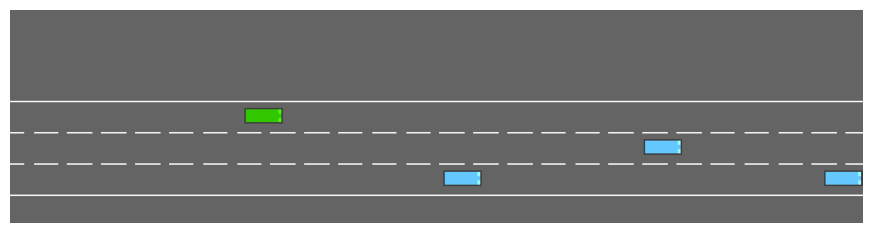

In [9]:
ENV_ID = "highway-v0"
ENV_CONFIG = {
    "lanes_count": 3,
    "vehicles_count": 12,
    "duration": 20,
    "simulation_frequency": 10,
    "policy_frequency": 2,
    "observation": {
        "type": "Kinematics",
        "vehicles_count": 13,  # Ego plus up to twelve nearby traffic vehicles.
        "features": ["presence", "x", "y", "vx", "vy"],
        "absolute": True,
        "normalize": False,
        "order": "sorted",
        "see_behind": True,
    },
    "action": {"type": "DiscreteMetaAction", "target_speeds": [20, 25, 30]},
    "collision_reward": -5.0,
    "high_speed_reward": 0.4,
    "right_lane_reward": 0.0,
    "reward_speed_range": [20, 30],
    "normalize_reward": False,
    "offroad_terminal": True,
    "offscreen_rendering": True,
}

def make_env(render_mode=None, config=None):
    # Copy nested config so experiments do not mutate the shared defaults.
    return gym.make(ENV_ID, config=copy.deepcopy(
        ENV_CONFIG if config is None else config), render_mode=render_mode)

preview = make_env(render_mode="rgb_array")
try:
    obs, info = preview.reset(seed=SEED)
    ACTIONS = dict(preview.unwrapped.action_type.actions)
    N_ACTIONS = preview.action_space.n
    print("Observation space:", preview.observation_space)
    print("Action space:", preview.action_space)
    print("Action IDs:", ACTIONS)
    display(pd.DataFrame(obs, columns=ENV_CONFIG["observation"]["features"]))
    plt.figure(figsize=(11, 3))
    plt.imshow(preview.render())
    plt.axis("off")
    plt.show()
finally:
    preview.close()

IDLE_ACTION = next(a for a, name in ACTIONS.items() if name == "IDLE")

## 3. Understand one interaction loop

A **policy** chooses an action from an observation. A random policy is enough to
check the environment before adding learning. Discrete meta-actions change target
lane or target speed; they are not direct steering angles or throttle values.
`IDLE` keeps the targets, so the vehicle continues driving.

- `reset(seed=...)` returns `(observation, info)` and starts a traffic scenario.
- `step(action)` returns `(next_observation, reward, terminated, truncated, info)`.
- `terminated` means a task ending, such as a crash here.
- `truncated` means a cutoff, such as the simulation duration.

Stop on **either** flag, then reset before stepping again. Seed both the traffic
and action sampler to repeat this demonstration. The `info` dictionary is useful
for diagnostics; it is not fed into our learning policy.

`info["rewards"]` contains raw reward features (for example, collision = 1),
not the weighted penalties. The scalar returned by `step` applies the weights.

In [10]:
env = make_env()
try:
    obs, info = env.reset(seed=SEED)
    env.action_space.seed(SEED)
    trajectory = []
    while True:
        action = env.action_space.sample()
        next_obs, reward, terminated, truncated, info = env.step(action)
        trajectory.append({
            "step": len(trajectory) + 1, "action": ACTIONS[action],
            "reward": reward, "speed_m_s": info["speed"],
            "crashed": info["crashed"],
            "terminated": terminated, "truncated": truncated,
        })
        obs = next_obs
        if terminated or truncated:
            break
    display(pd.DataFrame(trajectory).head(10))
    print("Episode return (sum of rewards):",
          round(sum(row["reward"] for row in trajectory), 3))
    print("Last transition:", trajectory[-1])
    print("Reward components in final info:", info.get("rewards", {}))
finally:
    env.close()

,step,action,reward,speed_m_s,crashed,terminated,truncated
0,1,LANE_LEFT,0.200000,25.000000,False,False,False
1,2,FASTER,0.319624,27.990612,False,False,False
2,3,FASTER,0.367699,29.192472,False,False,False
3,4,LANE_RIGHT,0.374341,29.675473,False,False,False
4,5,LANE_RIGHT,0.371561,29.869580,False,False,False
5,6,SLOWER,-4.819242,24.613533,True,True,False


Episode return (sum of rewards): -3.186
Last transition: {'step': 6, 'action': 'SLOWER', 'reward': np.float64(-4.819242435581077), 'speed_m_s': 24.61353287043275, 'crashed': True, 'terminated': True, 'truncated': False}
Reward components in final info: {'collision_reward': 1.0, 'right_lane_reward': np.float64(1.0), 'high_speed_reward': np.float64(0.45189391104730703), 'on_road_reward': 1.0}


**Try it:** replace the sampled action with `IDLE_ACTION`, then rerun this cell.
What changes in speed, reward, and episode length? A positive return by itself
does not mean safe driving; a policy can earn speed rewards before crashing.

## 4. Turn observations into a small discrete state

A raw matrix of continuous positions cannot be used directly as a practical
Q-table index. We summarize it into six integer features:

| Feature | Categories | Why include it? |
|---|---|---|
| Ego lane | 0, 1, 2 | Know road edges and current lane |
| Ego forward speed | below 22, 22–28, at least 28 m/s | Choose speed changes |
| Nearest observed front distance in ego lane | below 15, 15–30, 30–60, at least 60 m | Represent following space |
| Closing speed to that vehicle | below -2, -2–2, at least 2 m/s | Positive means approaching |
| Left adjacent lane | edge, observed blocked, observed clear | Summarize lane-change space |
| Right adjacent lane | edge, observed blocked, observed clear | Summarize lane-change space |

This gives $3 \times 3 \times 4 \times 3 \times 3 \times 3 = 972$ states and
4,860 state-action values for five actions. Some combinations are unreachable.
The distances are **vehicle-center distances**, not bumper gaps. Adjacent lanes
are called blocked when an observed vehicle is less than 20 m ahead or 15 m
behind. These thresholds are illustrative, not a safety guarantee.

We infer lanes from absolute `y` using the standard straight-road lane width of
4 m. This encoder is specific to this highway setup; it is not suitable for curved
roads. During lane changes, rounding approximates lane membership. Missing front
traffic maps to the largest distance bin and zero closing speed. “Observed clear”
only means no blocker was found in the available observation.

**Limitation:** different traffic scenes map to the same state. This abstraction
loses information, including lane-change progress, lateral velocity, rear closing
speed, and traffic intentions. It is not guaranteed to be Markov, so textbook
tabular Q-learning convergence guarantees do not directly apply.

In [11]:
LANE_WIDTH = 4.0
SPEED_EDGES = np.array([22.0, 28.0])
GAP_EDGES = np.array([15.0, 30.0, 60.0])
CLOSING_EDGES = np.array([-2.0, 2.0])
FRONT_CLEARANCE = 20.0
REAR_CLEARANCE = 15.0
STATE_SHAPE = (ENV_CONFIG["lanes_count"], len(SPEED_EDGES) + 1,
               len(GAP_EDGES) + 1, len(CLOSING_EDGES) + 1, 3, 3)

def encode_state(observation):
    """Use only the observation, never the simulator's hidden vehicle objects."""
    ego = observation[0]
    lane = int(np.clip(np.rint(ego[2] / LANE_WIDTH), 0, STATE_SHAPE[0] - 1))
    traffic = observation[1:]
    traffic = traffic[traffic[:, 0] > 0.5]  # Discard padding.
    lanes = np.rint(traffic[:, 2] / LANE_WIDTH).astype(int)
    dx = traffic[:, 1] - ego[1]
    front_indices = np.flatnonzero((lanes == lane) & (dx > 0))
    if len(front_indices):
        nearest = front_indices[np.argmin(dx[front_indices])]
        gap = float(dx[nearest])
        closing = float(ego[3] - traffic[nearest, 3])
    else:
        gap, closing = np.inf, 0.0

    def adjacent_status(candidate_lane):
        if not 0 <= candidate_lane < STATE_SHAPE[0]:
            return 0  # Road edge.
        blocked = np.any((lanes == candidate_lane)
                         & (dx > -REAR_CLEARANCE) & (dx < FRONT_CLEARANCE))
        return 1 if blocked else 2

    return (lane, int(np.digitize(ego[3], SPEED_EDGES)),
            int(np.digitize(gap, GAP_EDGES)),
            int(np.digitize(closing, CLOSING_EDGES)),
            adjacent_status(lane - 1), adjacent_status(lane + 1))

env = make_env()
try:
    obs, _ = env.reset(seed=SEED)
    state = encode_state(obs)
    print("Encoded state:", state)
    print("State count:", np.prod(STATE_SHAPE))
    print("Q-table shape:", STATE_SHAPE + (N_ACTIONS,))
finally:
    env.close()

Encoded state: (0, 1, 3, 1, 0, 2)
State count: 972
Q-table shape: (3, 3, 4, 3, 3, 3, np.int64(5))


## 5. Implement the Q-learning update

$Q(s,a)$ estimates the discounted future return from taking action $a$ in state
$s$, then following the greedy policy. It is learned from transitions:

$$Q(s,a) \leftarrow Q(s,a) + \alpha\left[
 r + \gamma\,\mathbf{1}_{\text{not terminated}}\max_{a'}Q(s',a') - Q(s,a)\right].$$

Here, $\alpha$ is the learning rate and $\gamma$ discounts future rewards.
The bracketed quantity is the **temporal-difference error**. The update is
*off-policy*: its target uses the greedy next action even when we explore.

With probability $\epsilon$, choose a random action; otherwise choose an action
with the largest Q-value. Random tie-breaking avoids always selecting the first
action when every value is zero. Exploration decays by episode, with a nonzero
floor. Evaluation uses $\epsilon=0$ and never updates the table.

We stop the rollout on either ending flag, but set the bootstrap to zero only for
`terminated`. Duration is treated as an external data-collection cutoff for a
continuing driving task. If you redefine the objective as a finite-horizon task,
include remaining time in the state and revisit the terminal target.

In [12]:
def select_action(q_table, state, epsilon, rng):
    if rng.random() < epsilon:
        return int(rng.integers(N_ACTIONS))
    values = q_table[state]
    best = np.flatnonzero(values == values.max())
    return int(rng.choice(best))


def q_learning_update(q_table, state, action, reward, next_state,
                      terminated, alpha, gamma):
    next_value = 0.0 if terminated else float(q_table[next_state].max())
    target = reward + gamma * next_value
    index = state + (action,)
    td_error = target - q_table[index]
    q_table[index] += alpha * td_error
    return float(td_error)

# A numerical example independent of the actual driving episode.
example_q = np.zeros((2, 2))
example_q[1] = [2.0, 4.0]
q_learning_update(example_q, (0,), 0, reward=1.0, next_state=(1,),
                  terminated=False, alpha=0.1, gamma=0.9)
print("New Q value:", example_q[0, 0], "= 0 + 0.1 * (1 + 0.9 * 4)")
assert np.isclose(example_q[0, 0], 0.46)

New Q value: 0.45999999999999996 = 0 + 0.1 * (1 + 0.9 * 4)


## 6. Train on randomized traffic

Each episode resets traffic with a different seed. The RNG for agent exploration
is separate from the simulator RNG. Re-running `train_q_learning` starts a fresh
zero table; it does not accidentally continue the previous run.

`epsilon_decay` multiplies exploration once per episode. Defaults reach the
0.05 floor near the end of 200 episodes. Change one setting at a time. More
training is useful only if the representation and reward support the behavior
you want to learn. We also count state-action visits: unvisited actions retain
zero estimates, which can beat negative learned values.

In [13]:
TRAIN_EPISODES = 200
TRAINING_SETTINGS = {
    "alpha": 0.15,
    "gamma": 0.95,
    "epsilon_start": 1.0,
    "epsilon_min": 0.05,
    "epsilon_decay": 0.985,
}

def train_q_learning(episodes, seed=SEED, alpha=0.15, gamma=0.95,
                     epsilon_start=1.0, epsilon_min=0.05, epsilon_decay=0.985):
    rng = np.random.default_rng(seed)
    q_table = np.zeros(STATE_SHAPE + (N_ACTIONS,), dtype=np.float64)
    visits = np.zeros_like(q_table, dtype=np.int64)
    records = []
    epsilon = epsilon_start
    env = make_env()
    try:
        for episode in range(episodes):
            obs, _ = env.reset(seed=seed + episode)
            state = encode_state(obs)
            episode_return, steps = 0.0, 0
            while True:
                action = select_action(q_table, state, epsilon, rng)
                next_obs, reward, terminated, truncated, info = env.step(action)
                next_state = encode_state(next_obs)
                q_learning_update(q_table, state, action, reward, next_state,
                                  terminated, alpha, gamma)
                visits[state + (action,)] += 1
                episode_return += reward
                steps += 1
                state = next_state
                if terminated or truncated:
                    break
            records.append({"episode": episode + 1, "return": episode_return,
                            "steps": steps, "epsilon": epsilon,
                            "crashed": bool(info["crashed"])})
            epsilon = max(epsilon_min, epsilon * epsilon_decay)
            if (episode + 1) % 50 == 0 or episode + 1 == episodes:
                print(f"Episode {episode + 1}/{episodes}: "
                      f"return={episode_return:.2f}, next epsilon={epsilon:.3f}")
    finally:
        env.close()
    return q_table, visits, pd.DataFrame(records)

q_table, visit_counts, training_history = train_q_learning(
    TRAIN_EPISODES, **TRAINING_SETTINGS)
print(f"Visited {np.count_nonzero(visit_counts)} / {visit_counts.size} state-action entries")

Episode 50/200: return=-3.57, next epsilon=0.470
Episode 100/200: return=12.12, next epsilon=0.221
Episode 150/200: return=12.76, next epsilon=0.104
Episode 200/200: return=12.26, next epsilon=0.050
Visited 476 / 4860 state-action entries


## 7. Inspect learning and the learned table

The plots use a rolling mean to make noisy trends easier to see. Training curves
mix learning with changing exploration, so they are not a fair final comparison.
A decreasing crash rate is encouraging; evaluate with exploration off next.

The table below shows one frequently visited state. Read its Q-values as
estimated discounted returns, not probabilities. A zero may simply be unvisited.

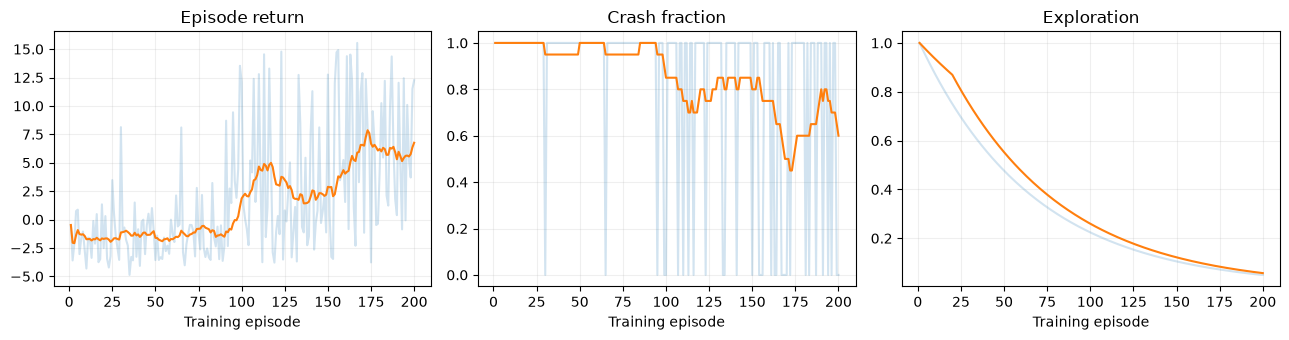

Most visited state: (np.int64(2), np.int64(1), np.int64(2), np.int64(2), np.int64(1), np.int64(0))


,action,Q value,visits
0,LANE_LEFT,-2.018051,9
1,IDLE,1.945040,210
2,LANE_RIGHT,0.920535,9
3,FASTER,0.454733,3
4,SLOWER,0.333458,5


In [14]:
window = min(20, len(training_history))
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, column, title in zip(axes, ["return", "crashed", "epsilon"],
                             ["Episode return", "Crash fraction", "Exploration"]):
    series = training_history[column].astype(float)
    ax.plot(training_history["episode"], series, alpha=0.2)
    ax.plot(training_history["episode"], series.rolling(window, min_periods=1).mean())
    ax.set(xlabel="Training episode", title=title)
    ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

most_visited = np.unravel_index(visit_counts.sum(axis=-1).argmax(), STATE_SHAPE)
print("Most visited state:", most_visited)
display(pd.DataFrame({"action": [ACTIONS[a] for a in range(N_ACTIONS)],
                      "Q value": q_table[most_visited],
                      "visits": visit_counts[most_visited]}))

## 8. Evaluate against simple baselines

Use the **same held-out traffic seeds** for all policies, with no table updates.
Seeds start at 100,000, outside the default training range. Equal initial seeds
make comparisons more useful, although different actions lead to different future
traffic interactions. Random and greedy tie-breaking use their own fixed RNGs.

Compare random actions, fixed `IDLE`, and learned greedy actions. Report return,
crash fraction, time-limit completion without termination, average forward speed,
and longitudinal distance. Distance is `x_final - x_initial` on this straight
highway. Mean speed is computed from that distance over simulated elapsed time,
then averaged across episodes. Early crashes shorten episodes, so inspect
completion and distance alongside speed. No energy metric is claimed yet.

Thirty episodes are an exploratory check. For research results, use more held-out
scenarios, multiple independent training seeds, uncertainty estimates, and separate
validation/test seed sets. Do not keep tuning against the final test set.

,episodes,mean_return,crash_fraction,completion_fraction,mean_speed_m_s,mean_distance_m
policy,,,,,,
Random,30,-1.504,0.867,0.133,24.828,210.046
Hold lane/speed,30,0.281,0.833,0.167,24.890,283.810
Q-learning,30,5.446,0.633,0.367,28.250,363.194


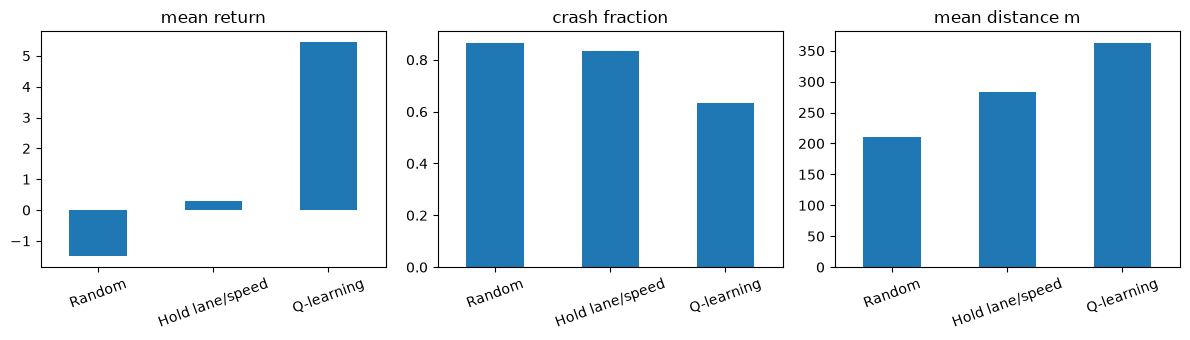

In [15]:
EVAL_EPISODES = 30
EVAL_SEEDS = list(range(100_000, 100_000 + EVAL_EPISODES))
assert not set(EVAL_SEEDS).intersection(range(SEED, SEED + TRAIN_EPISODES))

def evaluate(q_table, seeds):
    records = []
    env = make_env()
    try:
        for policy in ["Random", "Hold lane/speed", "Q-learning"]:
            for seed in seeds:
                rng = np.random.default_rng(seed + 1_000_000)
                obs, _ = env.reset(seed=seed)
                start_x = float(obs[0, 1])
                total_reward, steps = 0.0, 0
                while True:
                    if policy == "Random":
                        action = int(rng.integers(N_ACTIONS))
                    elif policy == "Hold lane/speed":
                        action = IDLE_ACTION
                    else:
                        action = select_action(q_table, encode_state(obs), 0.0, rng)
                    obs, reward, terminated, truncated, info = env.step(action)
                    total_reward += reward
                    steps += 1
                    if terminated or truncated:
                        break
                elapsed = steps / ENV_CONFIG["policy_frequency"]
                distance = float(obs[0, 1]) - start_x
                records.append({
                    "policy": policy, "seed": seed, "return": total_reward,
                    "crashed": bool(info["crashed"]),
                    "completed": bool(truncated and not terminated),
                    "elapsed_s": elapsed, "distance_m": distance,
                    "mean_speed_m_s": distance / elapsed,
                })
    finally:
        env.close()
    return pd.DataFrame(records)

evaluation = evaluate(q_table, EVAL_SEEDS)
summary = evaluation.groupby("policy", sort=False).agg(
    episodes=("seed", "count"), mean_return=("return", "mean"),
    crash_fraction=("crashed", "mean"), completion_fraction=("completed", "mean"),
    mean_speed_m_s=("mean_speed_m_s", "mean"), mean_distance_m=("distance_m", "mean"))
display(summary.round(3))
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for ax, metric in zip(axes, ["mean_return", "crash_fraction", "mean_distance_m"]):
    summary[metric].plot.bar(ax=ax, rot=20, title=metric.replace("_", " "))
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

**Interpret your run:** Does Q-learning reduce crashes versus random? Does it
beat the simple fixed-target policy? Is a higher return accompanied by longer
safe travel? If not, inspect exploration, visit counts, reward weights, and state
aliasing before assuming that more episodes will solve it. The `IDLE` baseline
can be competitive in light traffic.

## 9. Watch the greedy policy

The animation uses one held-out scenario and an RGB frame after each decision.
It illustrates behavior; the aggregate evaluation above is the evidence for
performance. `interval` controls playback, not simulation dynamics. The frame
list is kept small by the episode duration.

In [16]:
env = make_env(render_mode="rgb_array")
frames = []
try:
    obs, _ = env.reset(seed=EVAL_SEEDS[0])
    frames.append(env.render())
    rng = np.random.default_rng(SEED)
    while True:
        action = select_action(q_table, encode_state(obs), 0.0, rng)
        obs, reward, terminated, truncated, info = env.step(action)
        frames.append(env.render())
        if terminated or truncated:
            break
finally:
    env.close()

fig, ax = plt.subplots(figsize=(11, 3))
image = ax.imshow(frames[0])
ax.axis("off")
def update_frame(i):
    image.set_data(frames[i])
    ax.set_title(f"Greedy Q-learning: decision {i}")
    return (image,)

animation = FuncAnimation(fig, update_frame, frames=len(frames),
                          interval=1000 / ENV_CONFIG["policy_frequency"], blit=False)
plt.close(fig)
display(HTML(animation.to_jshtml()))

## 10. Save a run for later comparison

The Q-table is meaningful only with its matching state encoder, action mapping,
and environment. Save those settings and metrics together. This cell replaces
files of the same name under `artifacts/` in the current working directory.
Keep separate folders for experiments you want to retain.

In [17]:
PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
                    if (p / "environments/sensor_highway/env.py").exists())
OUTPUT_DIR = PROJECT_ROOT / "runs/tutorial/highway_q_learning"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
metadata = {
    "environment_id": ENV_ID, "environment_config": ENV_CONFIG,
    "training_episodes": TRAIN_EPISODES, "training_seed": SEED,
    "training_settings": TRAINING_SETTINGS, "evaluation_seeds": EVAL_SEEDS,
    "actions": ACTIONS, "state_shape": list(STATE_SHAPE),
    "encoder": {"lane_width": LANE_WIDTH, "speed_edges": SPEED_EDGES.tolist(),
                "gap_edges": GAP_EDGES.tolist(), "closing_edges": CLOSING_EDGES.tolist(),
                "front_clearance": FRONT_CLEARANCE, "rear_clearance": REAR_CLEARANCE},
    "python": sys.version, "package_versions": PACKAGE_VERSIONS,
}
np.savez_compressed(OUTPUT_DIR / "q_learning.npz", q_table=q_table, visits=visit_counts)
(OUTPUT_DIR / "metadata.json").write_text(json.dumps(metadata, indent=2))
training_history.to_csv(OUTPUT_DIR / "training.csv", index=False)
evaluation.to_csv(OUTPUT_DIR / "evaluation.csv", index=False)
summary.to_csv(OUTPUT_DIR / "summary.csv")
print("Saved to:", OUTPUT_DIR.resolve())

# Reload only with the same encoder, action mapping, and environment configuration.
with np.load(OUTPUT_DIR / "q_learning.npz", allow_pickle=False) as saved:
    restored_q = saved["q_table"]
assert np.array_equal(restored_q, q_table)

Saved to: runs/tutorial/highway_q_learning


## 11. Experiments to try

For each experiment, predict the outcome, change one setting, restart the kernel,
and run all cells. Record the metrics, not just the animation.

1. **Traffic:** change `vehicles_count` from 12 to 20. Also increase observation
   `vehicles_count` to 21 if you want to retain capacity for all traffic within
   perception range. How does this change the difficulty?
2. **Learning time:** compare 200 and 1,000 episodes. The current exploration
   schedule reaches its floor early in a longer run; consider `epsilon_decay=0.997`.
3. **Safety weight:** compare `collision_reward=-1`, `-5`, and `-10`, with reward
   normalization still disabled. Track distance and crashes as well as return.
   Returns from different reward definitions are not directly comparable.
4. **State resolution:** change `GAP_EDGES` and observe visit coverage. Finer bins
   distinguish scenes but need more experience. Restart and rebuild the table.
5. **Discounting:** compare `gamma=0.8` with `0.99`. With a 0.5-second decision
   interval, these imply very different effective planning horizons.
6. **Repeatability:** train with three distinct `SEED` values and compare on the
   same held-out scenarios. How much variation comes from training randomness?

## 12. Connect this to your sensor project

The next step is a Gymnasium wrapper that separates **simulator truth** from
**information available to the agent**. It can mask or corrupt selected observation
features based on sensor activation. Keep the observation shape fixed and include
availability flags and measurement age. Never let the encoder recover hidden
traffic from simulator objects when a sensor is off.

Then add a joint driving/sensing action and separate reward components for safety,
performance, and modeled energy. Integrate power over simulated time to obtain
energy; clearly state the assumed sensor and processing costs. Start with one
sensor switch and compare always-on and always-off policies before expanding.
Each added sensor and action increases table size and observation history needs;
this is a reason to later explore DQN and memory-based policies.

Your proposal specifies collisions should not terminate an episode. This notebook
uses stock collision termination. A nonterminating design requires more than
ignoring `terminated`: define what happens to crashed vehicles, post-crash driving,
recovery, and subsequent rewards inside a custom environment, then test it.
Otherwise, a damaged stopped vehicle or early ending can create unintended energy
incentives. Establish that design before interpreting sensor-energy tradeoffs.

This tutorial provides the environment/algorithm/evaluation building blocks.
Minimum time-to-collision, energy per kilometer, objective weight sweeps, safety
thresholds, and Pareto analysis remain future project work.

## References and troubleshooting

- [HighwayEnv quick start](https://highway-env.farama.org/quickstart/)
- [Highway configuration and rewards](https://highway-env.farama.org/environments/highway/)
- [Kinematic observations](https://highway-env.farama.org/observations/)
- [Discrete meta-actions](https://highway-env.farama.org/actions/)
- [Gymnasium basic usage](https://gymnasium.farama.org/introduction/basic_usage/)
- [Termination, truncation, and bootstrapping](https://gymnasium.farama.org/introduction/migration_guide/)

**Import error:** check the interpreter printed in section 1 and select `.venv`.
**Unknown environment ID:** run the imports and registration before `gym.make`.
**Slow run:** reduce episode counts first; leave rendering out of training.
**Poor results:** examine visits and held-out crash rates; this is a lossy state
abstraction, not a guaranteed safe or optimal controller.
**Changed config or out-of-order cells:** restart and run all to keep the encoder,
Q-table, training logs, and metadata consistent.